# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ ] Visualize a few images from the dataset to understand what the data looks like.

In [7]:
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
import numpy as np

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [8]:
# Inspect the shapes of the datasets
#Inspect the shapes of the datasets
print("X_train shape:", X_train.shape)   # (60000, 28, 28)
print("y_train shape:", y_train.shape)   # (60000,)
print("X_test shape: ", X_test.shape)    # (10000, 28, 28)
print("y_test shape: ", y_test.shape)    # (10000,)
print("Pixel range:", X_train.min(), "to", X_train.max())

#Check class balance
print("\nTraining samples per class:")
for i, name in enumerate(class_names):
    print(f"  {i} {name:12s}: {np.sum(y_train == i)}")

#Add a channel dimension (Conv2D expects (height, width, channels))
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)
print("\nAfter reshape:", X_train.shape, X_test.shape)


# Convert labels to one-hot encoding
#Keep the integer labels too, for plotting and confusion matrices later
y_train_int, y_test_int = y_train, y_test
y_train = to_categorical(y_train_int, num_classes=10)
y_test = to_categorical(y_test_int, num_classes=10)
print("One-hot y_train shape:", y_train.shape)   # (60000, 10)
print("Example: label", y_train_int[0], "->", y_train[0])



X_train shape: (60000, 28, 28)
y_train shape: (60000,)
X_test shape:  (10000, 28, 28)
y_test shape:  (10000,)
Pixel range: 0.0 to 1.0

Training samples per class:
  0 T-shirt/top : 6000
  1 Trouser     : 6000
  2 Pullover    : 6000
  3 Dress       : 6000
  4 Coat        : 6000
  5 Sandal      : 6000
  6 Shirt       : 6000
  7 Sneaker     : 6000
  8 Bag         : 6000
  9 Ankle boot  : 6000

After reshape: (60000, 28, 28, 1) (10000, 28, 28, 1)
One-hot y_train shape: (60000, 10)
Example: label 9 -> [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


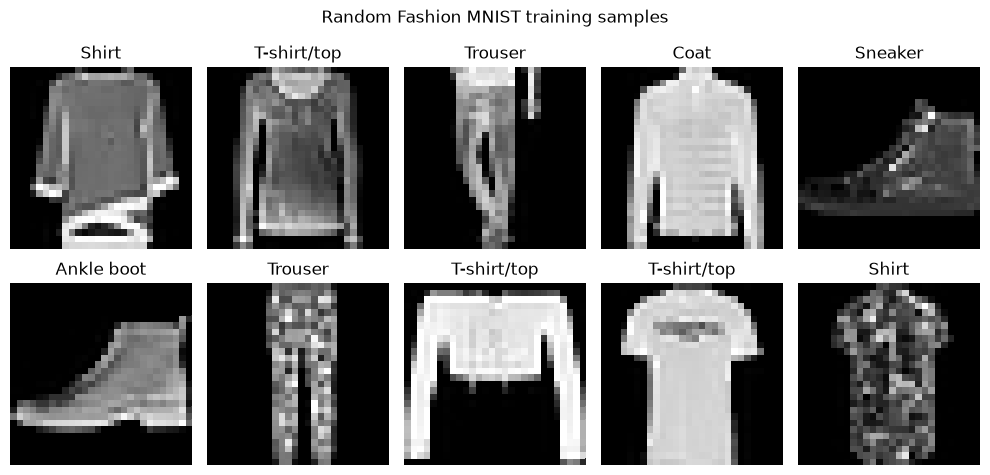

In [9]:
import matplotlib.pyplot as plt
# Verify the data looks as expected
#Visualize a few images
#Grid of random samples
plt.figure(figsize=(10, 5))
for i, idx in enumerate(np.random.choice(len(X_train), 10, replace=False)):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[idx].squeeze(), cmap='gray')
    plt.title(class_names[y_train_int[idx]])
    plt.axis('off')
plt.suptitle("Random Fashion MNIST training samples")
plt.tight_layout()
plt.show()


Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

**Your answer here**

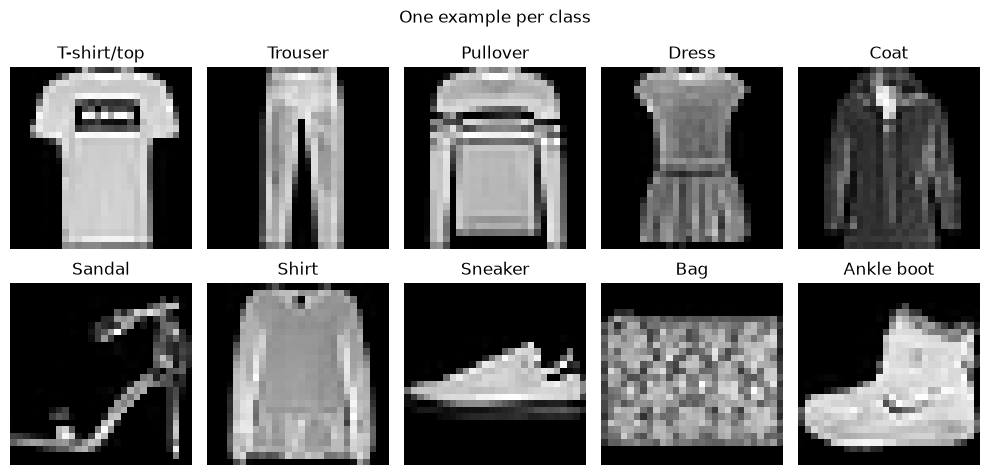

In [10]:
#One example of each class
plt.figure(figsize=(10, 5))
for c in range(10):
    idx = np.where(y_train_int == c)[0][0]
    plt.subplot(2, 5, c + 1)
    plt.imshow(X_train[idx].squeeze(), cmap='gray')
    plt.title(class_names[c])
    plt.axis('off')
plt.suptitle("One example per class")
plt.tight_layout()
plt.show()

In [ ]:
Classes like T-shirt/top, Shirt, Pullover, and Coat look similar, so expect the model to confuse them most often.60,000 training and 10,000 test images, each 28×28 grayscale. The classes are perfectly balanced at 6,000 per class in training, so accuracy is a reasonable metric.

# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ ] Create a simple linear regression model using Keras.
- [ ] Compile the model with an appropriate loss function and optimizer.
- [ ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

In [12]:
from keras.models import Sequential
from keras.layers import Dense, Flatten
import tensorflow as tf

# Create a simple linear regression model 
# You can use `model.add(<layer>)` to add layers to the model
model = Sequential()
model.add(Flatten(input_shape=(28, 28, 1)))
model.add(Dense(10))   # no activation = linear (one output per class)

# Compile the model using `model.compile()`
model.compile(optimizer='adam',
                 loss=tf.keras.losses.CategoricalCrossentropy(from_logits=True),
                 metrics=['accuracy'])

# Train the model with `model.fit()`
baseline_history = model.fit(X_train, y_train,
                                validation_split=0.1,
                                epochs=10, batch_size=128, verbose=2)

# Evaluate the model with `model.evaluate()`
base_loss, base_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Baseline test accuracy: {base_acc:.4f}")

Epoch 1/10
422/422 - 0s - 1ms/step - accuracy: 0.7475 - loss: 0.7646 - val_accuracy: 0.8155 - val_loss: 0.5519
Epoch 2/10
422/422 - 0s - 430us/step - accuracy: 0.8244 - loss: 0.5281 - val_accuracy: 0.8282 - val_loss: 0.4946
Epoch 3/10
422/422 - 0s - 453us/step - accuracy: 0.8398 - loss: 0.4817 - val_accuracy: 0.8402 - val_loss: 0.4630
Epoch 4/10
422/422 - 0s - 449us/step - accuracy: 0.8454 - loss: 0.4582 - val_accuracy: 0.8445 - val_loss: 0.4522
Epoch 5/10
422/422 - 0s - 448us/step - accuracy: 0.8488 - loss: 0.4430 - val_accuracy: 0.8487 - val_loss: 0.4357
Epoch 6/10
422/422 - 0s - 453us/step - accuracy: 0.8521 - loss: 0.4340 - val_accuracy: 0.8500 - val_loss: 0.4303
Epoch 7/10
422/422 - 0s - 461us/step - accuracy: 0.8551 - loss: 0.4263 - val_accuracy: 0.8528 - val_loss: 0.4230
Epoch 8/10
422/422 - 0s - 446us/step - accuracy: 0.8569 - loss: 0.4186 - val_accuracy: 0.8520 - val_loss: 0.4271
Epoch 9/10
422/422 - 0s - 440us/step - accuracy: 0.8587 - loss: 0.4136 - val_accuracy: 0.8507 - va

Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

**Your answer here**
The linear baseline reached 84.18% test accuracy, with a final validation accuracy of 85.62% and training accuracy of 85.95%. This is far above the 10% chance level and about what I expected for a model with no hidden layers. It shows that a large share of the class information in Fashion MNIST can be separated linearly from raw pixel values.
The performance plateaus at this level because a linear model learns one fixed weight per pixel per class, which amounts to a single rigid template for each class. It cannot model non-linear interactions between pixels, and because Flatten discards the 2D layout, it has no way to recognize the same pattern (such as a sleeve or collar) when it appears in a different position. Classes with high within-class variation or strong visual overlap, such as Shirt, T-shirt/top, Pullover, and Coat, are where a single template per class breaks down, so I expect most errors to come from those classes. 

# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

In [16]:
from keras.layers import Conv2D, MaxPooling2D

# Reshape the data to include the channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Create a simple CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

# One-hot labels + softmax output -> categorical crossentropy
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# Train the model
history = model.fit(X_train, y_train,
                    validation_split=0.1,
                    epochs=10, batch_size=128, verbose=2)

# Evaluate the model
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"CNN test accuracy: {test_acc:.4f}")
print(f"Improvement over baseline: {(test_acc - base_acc) * 100:.2f} percentage points") 

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       692,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 693,962 (2.65 MB)

 Trainable params: 693,962 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 - 3s - 8ms/step - accuracy: 0.8368 - loss: 0.4663 - val_accuracy: 0.8762 - val_loss: 0.3362
Epoch 2/10
422/422 - 3s - 6ms/step - accuracy: 0.8909 - loss: 0.3077 - val_accuracy: 0.8992 - val_loss: 0.2911
Epoch 3/10
422/422 - 3s - 6ms/step - accuracy: 0.9049 - loss: 0.2649 - val_accuracy: 0.9020 - val_loss: 0.2710
Epoch 4/10
422/422 - 3s - 6ms/step - accuracy: 0.9131 - loss: 0.2386 - val_accuracy: 0.9082 - val_loss: 0.2598
Epoch 5/10
422/422 - 3s - 6ms/step - accuracy: 0.9230 - loss: 0.2099 - val_accuracy: 0.9087 - val_loss: 0.2456
Epoch 6/10
422/422 - 3s - 7ms/step - accuracy: 0.9303 - loss: 0.1918 - val_accuracy: 0.9108 - val_loss: 0.2464
Epoch 7/10
422/422 - 3s - 7ms/step - accuracy: 0.9352 - loss: 0.1748 - val_accuracy: 0.9128 - val_loss: 0.2427
Epoch 8/10
422/422 - 3s - 8ms/step - accuracy: 0.9431 - loss: 0.1582 - val_accuracy: 0.9177 - val_loss: 0.2350
Epoch 9/10
422/422 - 3s - 8ms/step - accuracy: 0.9478 - loss: 0.1441 - val_accuracy: 0.9137 - val_loss: 0.2434
E

Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

**Your answer here**
This run reached 90.76% test accuracy, a 6.58 point gain over the baseline.so the CNN removed about 42% of the baseline’s mistakes. Test accuracy is close to the final validation accuracy (91.37%), so the validation estimate was reasonably reliable.
The improvement is attributable to the CNN’s use of local spatial structure, weight sharing across the image, and non-linear feature interactions, none of which the flattened linear model can capture.

# 4. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.

In [21]:
import keras
from keras.layers import Dropout
def build_cnn(filters=32, kernel_size=(3, 3), dropout=0.0):
    model = Sequential([
        Conv2D(filters, kernel_size, activation='relu', input_shape=(28, 28, 1)),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dropout(dropout),
        Dense(128, activation='relu'),
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def run_experiment(filters=32, dropout=0.0, seeds=(0, 1, 2), epochs=10):
    val_accs, test_accs = [], []
    for seed in seeds:
        keras.utils.set_random_seed(seed)
        model = build_cnn(filters=filters, dropout=dropout)
        h = model.fit(X_train, y_train, validation_split=0.1,
                      epochs=epochs, batch_size=128, verbose=0)
        val_accs.append(h.history['val_accuracy'][-1])
        test_accs.append(model.evaluate(X_test, y_test, verbose=0)[1])
    return (np.mean(val_accs), np.std(val_accs),
            np.mean(test_accs), np.std(test_accs))

results = {}

In [22]:
# A. Test Hyperparameters
for f in [16, 32, 64]:
    vm, vs, tm, ts = run_experiment(filters=f, dropout=0.0)
    results[('filters', f)] = (vm, vs, tm, ts)
    print(f"filters={f:3d} | val {vm:.4f} ± {vs:.4f} | test {tm:.4f} ± {ts:.4f}")

filters= 16 | val 0.9118 ± 0.0034 | test 0.9030 ± 0.0031
filters= 32 | val 0.9123 ± 0.0018 | test 0.9062 ± 0.0016
filters= 64 | val 0.9127 ± 0.0012 | test 0.9079 ± 0.0020


In [23]:
# B. Test presence or absence of regularization
# B. Test presence or absence of regularization: dropout (filters fixed at 32)
for d in [0.0, 0.25, 0.5]:
    vm, vs, tm, ts = run_experiment(filters=32, dropout=d)
    results[('dropout', d)] = (vm, vs, tm, ts)
    print(f"dropout={d:.2f} | val {vm:.4f} ± {vs:.4f} | test {tm:.4f} ± {ts:.4f}")

dropout=0.00 | val 0.9123 ± 0.0018 | test 0.9062 ± 0.0016
dropout=0.25 | val 0.9159 ± 0.0015 | test 0.9111 ± 0.0009


KeyboardInterrupt: 

In [ ]:
# C. Combining best settings from A and B, since the effects may interact
# Filling best_f and best_d from the validation accuracies above
best_f, best_d = 64, 0.25   # <- replace with your winners
vm, vs, tm, ts = run_experiment(filters=best_f, dropout=best_d)
print(f"COMBINED filters={best_f}, dropout={best_d} | val {vm:.4f} ± {vs:.4f} | test {tm:.4f} ± {ts:.4f}")

COMBINED filters=64, dropout=0.25 | val 0.9181 ± 0.0023 | test 0.9142 ± 0.0011


Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

**Your answer here**
I tested two things on the CNN: the number of filters (16, 32, 64) and dropout (0, 0.25, 0.5). Each setting was run 3 times with different random seeds, and I averaged the results.
Number of filters: This made only a small difference.More filters may help a little, but the effect is small. One convolutional layer probably already captures most of the useful patterns in these small 28×28 images, so extra filters add little new information.
Dropout: This helped more. Dropout of 0.25 raised test accuracy from 90.62% to 91.11% and validation accuracy from 91.23% to 91.59%, and the results were consistent across seeds.
64 filters with dropout 0.25 gave the best results, with 91.81% validation accuracy and 91.42% test accuracy.

# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ ] Compile the final model with the best hyperparameters and regularization techniques.
- [ ] Train the final model on the training set and evaluate it on the test set.
- [ ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

Model: "sequential_45"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_43 (Conv2D)              │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_43 (MaxPooling2D) │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_45 (Flatten)            │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_39 (Dropout)            │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_88 (Dense)                │ (None, 128)            │     1,384,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_89 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,386,506 (5.29 MB)

 Trainable params: 1,386,506 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 - 9s - 22ms/step - accuracy: 0.8416 - loss: 0.4472 - val_accuracy: 0.8822 - val_loss: 0.3307
Epoch 2/10
422/422 - 11s - 25ms/step - accuracy: 0.8917 - loss: 0.3007 - val_accuracy: 0.8943 - val_loss: 0.2912
Epoch 3/10
422/422 - 11s - 26ms/step - accuracy: 0.9063 - loss: 0.2588 - val_accuracy: 0.9040 - val_loss: 0.2711
Epoch 4/10
422/422 - 10s - 23ms/step - accuracy: 0.9157 - loss: 0.2311 - val_accuracy: 0.9085 - val_loss: 0.2618
Epoch 5/10
422/422 - 10s - 24ms/step - accuracy: 0.9239 - loss: 0.2091 - val_accuracy: 0.9102 - val_loss: 0.2485
Epoch 6/10
422/422 - 11s - 25ms/step - accuracy: 0.9318 - loss: 0.1879 - val_accuracy: 0.9098 - val_loss: 0.2539
Epoch 7/10
422/422 - 11s - 27ms/step - accuracy: 0.9368 - loss: 0.1724 - val_accuracy: 0.9147 - val_loss: 0.2468
Epoch 8/10
422/422 - 11s - 26ms/step - accuracy: 0.9414 - loss: 0.1596 - val_accuracy: 0.9133 - val_loss: 0.2484
Epoch 9/10
422/422 - 12s - 28ms/step - accuracy: 0.9461 - loss: 0.1443 - val_accuracy: 0.9145 - v

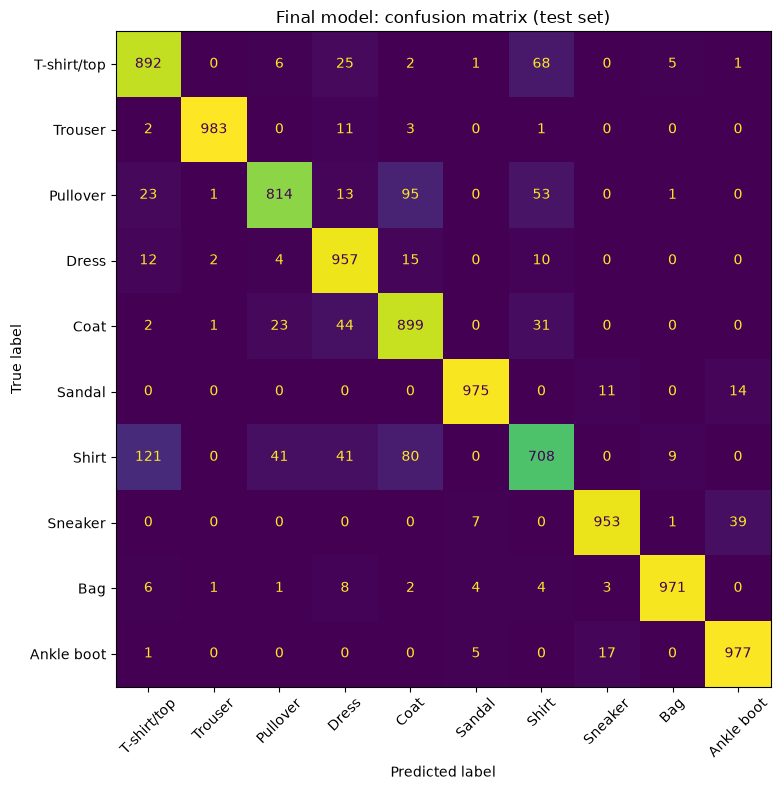

Most common mistakes (true -> predicted):
  Shirt        -> T-shirt/top : 121
  Pullover     -> Coat        : 95
  Shirt        -> Coat        : 80
  T-shirt/top  -> Shirt       : 68
  Pullover     -> Shirt       : 53


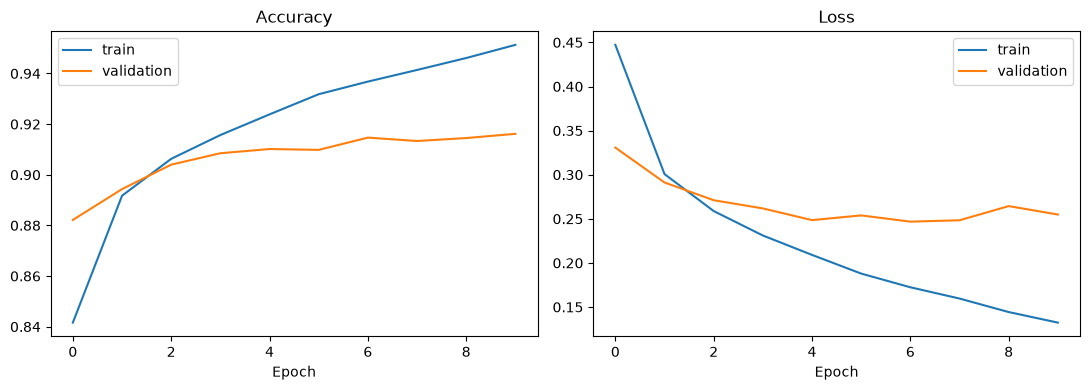

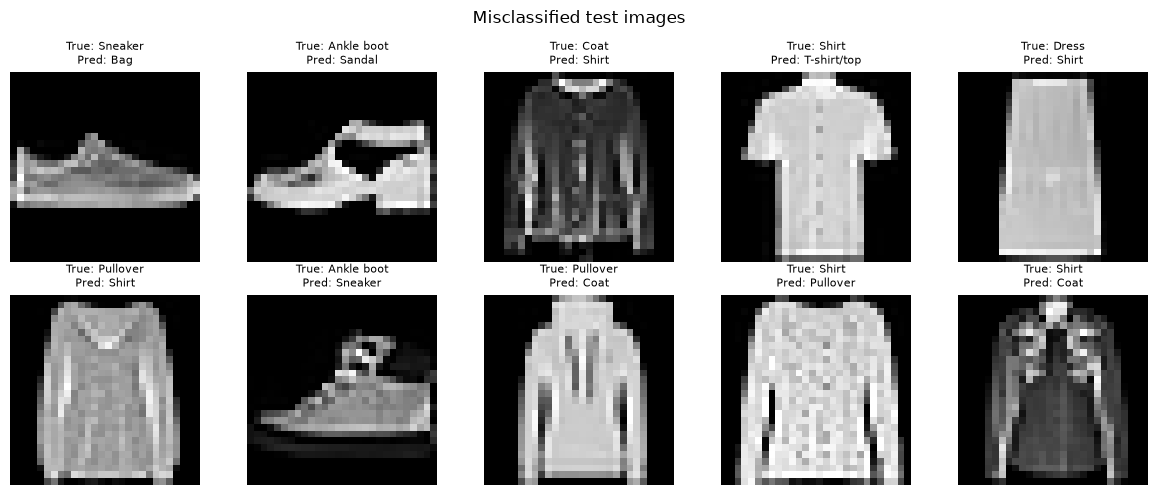

In [25]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
#Build and compile the final model
keras.utils.set_random_seed(0)

final_model = Sequential([
    Conv2D(64, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dropout(0.25),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

final_model.compile(optimizer='adam',
                    loss='categorical_crossentropy',
                    metrics=['accuracy'])
final_model.summary()

#Train (same setup as the experiments)
final_history = final_model.fit(X_train, y_train,
                                validation_split=0.1,
                                epochs=10, batch_size=128, verbose=2)

#Evaluate on the test set
final_loss, final_acc = final_model.evaluate(X_test, y_test, verbose=0)
print(f"\nFinal test loss:     {final_loss:.4f}")
print(f"Final test accuracy: {final_acc:.4f}")
print(f"Improvement over baseline (84.18%): {(final_acc - 0.8418) * 100:.2f} points")

#Other metrics: per-class precision / recall / F1
y_prob = final_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

print("\n", classification_report(y_true, y_pred, target_names=class_names, digits=3))

#Confusion matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Final model: confusion matrix (test set)")
plt.tight_layout()
plt.show()

#Most confused class pairs
off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
print("Most common mistakes (true -> predicted):")
for idx in np.dstack(np.unravel_index(np.argsort(-off_diag.ravel())[:5], cm.shape))[0]:
    t, p = idx
    print(f"  {class_names[t]:12s} -> {class_names[p]:12s}: {off_diag[t, p]}")

# Training curves
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(final_history.history['accuracy'], label='train')
axes[0].plot(final_history.history['val_accuracy'], label='validation')
axes[0].set_title('Accuracy'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(final_history.history['loss'], label='train')
axes[1].plot(final_history.history['val_loss'], label='validation')
axes[1].set_title('Loss'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout()
plt.show()

# A few misclassified examples
wrong = np.where(y_pred != y_true)[0][:10]
plt.figure(figsize=(12, 5))
for i, idx in enumerate(wrong):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx].squeeze(), cmap='gray')
    plt.title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}", fontsize=8)
    plt.axis('off')
plt.suptitle("Misclassified test images")
plt.tight_layout()
plt.show()

Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

**Your answer here**
The final model reached 91.29% test accuracy. The linear baseline reached 84.18%, so the final model is 7.11 points better. In terms of mistakes, the error rate dropped from 15.82% to 8.71%. The final model is also better than my first CNN, which reached 90.76% with no dropout and 32 filters, a gain of about 0.5 points. That gain is small, but dropout and extra filters helped in the Section 4 experiments too, where this setting averaged 91.42% across 3 seeds.
A second convolutional layer could capture finer details such as collars and sleeves, which might help with the Shirt confusions. Data augmentation and early stopping could reduce overfitting.
The model still overfits somewhat. Training accuracy is 95.1%, but validation accuracy is only about 91.6%. Most of the remaining mistakes (about 63%) are among Shirt, T-shirt/top, Pullover, and Coat, which look very similar at 28×28 pixels. Shirt is the hardest class, with an F1 score of 0.755.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/09/2026`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.